# Task 4 – Netflix Content Segmentation (K-Means Clustering)

**Goal:** group Netflix titles into meaningful clusters **without using any labels**. This is *unsupervised learning*: I don't tell the algorithm what the groups are, it finds titles that resemble each other and I then work out what each group means.

In [3]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Step 0 – Load and clean the data

Before any modelling I load the file and tidy it. What I do, and why:

- **Remove exact duplicate rows** (there are none in this file, but it is a good habit).
- **Parse `date_added`.** In this dataset dates look like `9/25/2021`, so I tell pandas the exact format.
- **Missing values** are not blank here. The file writes `Not Given` for unknown directors and countries, and I keep that in mind (for example `has_director` is 0 when the director is `Not Given`).
- **Turn `duration` into a number.** `"90 min"` becomes 90 and `"2 Seasons"` becomes 2.
- **Simplify genre names.** Netflix names the same genre differently for movies and shows (`Dramas` vs `TV Dramas`, `International Movies` vs `International TV Shows`). I merge them so a genre means the same thing for both types.

In [4]:
DATA_PATH = "Dataset.csv"      # change this if the file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)

# Dates (format in this file is month/day/year)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Duration as a number: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Helpers for comma separated columns
def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' -> 'Dramas';  'International Movies' -> 'International'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    name = re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)
    return name

# Handy columns used by several tasks
df["genre_list"] = df["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
df["n_genres"] = df["genre_list"].apply(len)
df["country_main"] = df["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
df["has_director"] = (df["director"].str.strip() != "Not Given").astype(int)
df["years_to_add"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 0/1 columns for the 30 most common (simplified) genres, most common first
top_genres = pd.Series([g for lst in df["genre_list"] for g in lst]).value_counts().head(30).index.tolist()
genre_cols = []
for g in top_genres:
    col = "genre_" + g
    df[col] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

print(df["type"].value_counts().to_dict(), "| date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())
df.head(3)

Dataset shape: (8790, 10)
{'Movie': 6126, 'TV Show': 2664} | date range: 2008-01-01 to 2021-09-25


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_Spanish-Language,genre_Korean,genre_Classic,genre_LGBTQ,genre_Mysteries,genre_Science & Nature,genre_Cult,genre_Anime Features,genre_Other,genre_Teen
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,0,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,0,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,1,0,0,0,0,0


## Step 1 – Prepare numerical and categorical features

K-Means works with numbers and distances, so everything has to be numeric:
- `release_year` – how old the title is.
- `movie_minutes` and `seasons` – length. I keep them as two columns (0 for the type that doesn't apply) because minutes and seasons are not comparable.
- `years_to_add` – how long after release Netflix added it (fresh vs library content).
- `n_genres`, `has_director`, `is_tv`.
- 0/1 columns for the **10 most common genres**.

In [5]:
seg = pd.DataFrame(index=df.index)
seg["release_year"] = df["release_year"]
seg["movie_minutes"] = np.where(df["type"] == "Movie", df["duration_num"], 0)
seg["seasons"] = np.where(df["type"] == "TV Show", df["duration_num"], 0)
seg["years_to_add"] = df["years_to_add"]
seg["n_genres"] = df["n_genres"]
seg["has_director"] = df["has_director"]
seg["is_tv"] = (df["type"] == "TV Show").astype(int)
for g in genre_cols[:10]:
    seg[g] = df[g]

print("Features:", list(seg.columns))

# K-Means uses distances, so put every feature on the same scale
X_scaled = StandardScaler().fit_transform(seg)

Features: ['release_year', 'movie_minutes', 'seasons', 'years_to_add', 'n_genres', 'has_director', 'is_tv', 'genre_International', 'genre_Dramas', 'genre_Comedies', 'genre_Action & Adventure', 'genre_Romantic', 'genre_Documentaries', 'genre_Independent', 'genre_Children & Family', 'genre_Thrillers', 'genre_Crime']


## Step 2 – Apply the clustering algorithm

The big question in K-Means is *how many clusters (k)?* I try k = 3 to 9 and look at two signals (there is no razor-sharp elbow in this data, which is common with real catalogs, so I'll explain how I choose below):
- **Elbow (inertia):** how tightly packed the clusters are. It always falls as k grows, so I look for the bend where extra clusters stop helping much.
- **Silhouette score:** how well separated the clusters are, from -1 to 1 (higher is better).

*Why I start at 3 and not 2:* with k = 2 the algorithm simply re-discovers Movie vs TV Show, which we already know. I want groups that tell us something new.

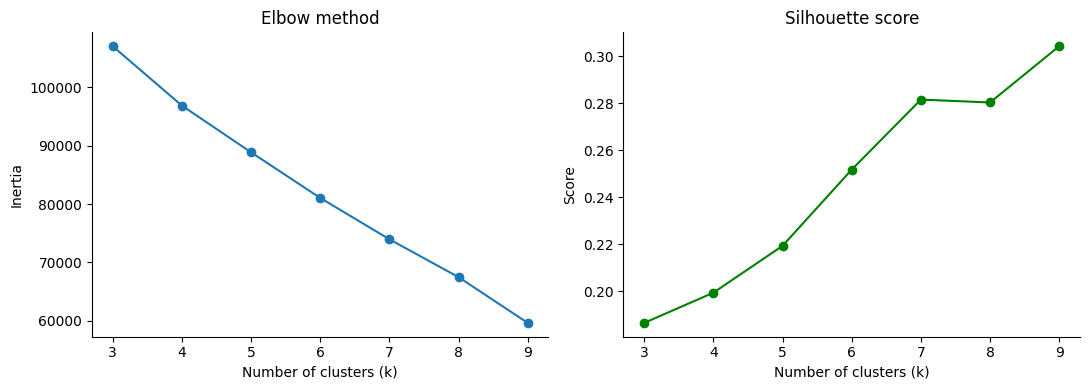

 k  inertia  silhouette
 3 107062.0       0.186
 4  96881.0       0.199
 5  88872.0       0.219
 6  81050.0       0.252
 7  73964.0       0.282
 8  67469.0       0.280
 9  59625.0       0.304


In [6]:
k_values = list(range(3, 10))
inertia, silhouette = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_, sample_size=4000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_values, inertia, marker="o")
axes[0].set_title("Elbow method"); axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouette, marker="o", color="green")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"k": k_values, "inertia": np.round(inertia), "silhouette": np.round(silhouette, 3)}).to_string(index=False))

In [7]:
# The silhouette score keeps creeping upward as clusters get smaller, so "the highest score" would just pick
# the largest k I tried. Instead I take the FIRST local peak: the first k where adding another cluster stops helping.
K = next((k_values[i] for i in range(len(k_values) - 1) if silhouette[i] >= silhouette[i + 1]), k_values[-1])
# (Change K by hand if you prefer another value after looking at the plots.)
print("Chosen k =", K)

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
df["cluster"] = kmeans.labels_
print(df["cluster"].value_counts().sort_index())

Chosen k = 7
cluster
0    1549
1     683
2     469
3     608
4    2679
5    2164
6     638
Name: count, dtype: int64


## Step 3 – Identify content groups & Step 4 – Visualize the clusters

My data has about 16 dimensions, which I can't draw. **PCA** squashes them into 2 new axes that keep as much of the variation as possible, so I can see the clusters on a flat scatter plot. (Overlap in this picture doesn't always mean overlap in reality, since two dimensions can't hold everything.)

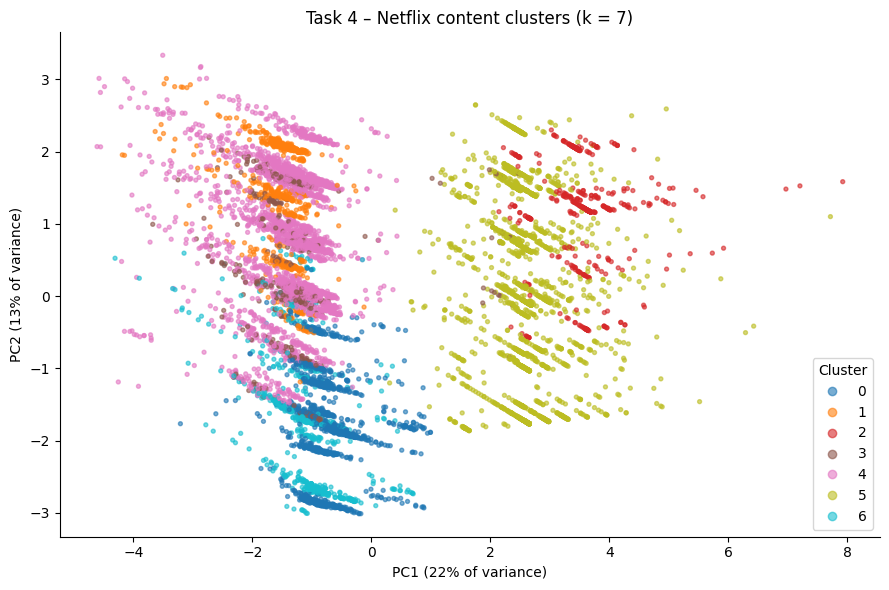

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab10", s=8, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.title(f"Task 4 – Netflix content clusters (k = {K})")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.tight_layout()
plt.show()

## Step 5 – Interpret cluster characteristics

Now the detective part: for each cluster I summarise the real titles inside it (share of TV shows, average year, length, most common genres and rating). Averages are only shown when a cluster has at least 30 titles of that type, because an average over a handful of titles would be misleading. Those numbers are what let me give each cluster a sensible name.

In [9]:
def top_genres_of(group, n=3):
    items = [simplify_genre(g) for text in group["listed_in"] for g in split_items(text)]
    return ", ".join(pd.Series(items).value_counts().head(n).index)

profile = df.groupby("cluster").apply(lambda g: pd.Series({
    "titles": len(g),
    "% TV shows": round((g["type"] == "TV Show").mean() * 100, 1),
    "avg release year": round(g["release_year"].mean(), 1),
    "avg movie minutes": round(g.loc[g["type"] == "Movie", "duration_num"].mean(), 1) if (g["type"] == "Movie").sum() >= 30 else None,
    "avg seasons": round(g.loc[g["type"] == "TV Show", "duration_num"].mean(), 2) if (g["type"] == "TV Show").sum() >= 30 else None,
    "% with director": round(g["has_director"].mean() * 100, 1),
    "top genres": top_genres_of(g),
    "most common rating": g["rating"].mode().iloc[0],
}))
profile

,titles,% TV shows,avg release year,avg movie minutes,avg seasons,% with director,top genres,most common rating
cluster,,,,,,,,
0,1549,0.0,2016.6,80.6,NaN,93.5,"Documentaries, Stand-Up Comedy, International",TV-MA
1,683,0.0,2014.3,101.5,NaN,99.3,"Independent, Dramas, International",TV-MA
2,469,100.0,2017.7,NaN,1.71,14.7,"Crime, International, Dramas",TV-MA
3,608,5.1,2014.8,107.2,1.13,95.1,"Thrillers, International, Dramas",TV-MA
4,2679,0.1,2010.2,113.2,NaN,98.8,"International, Dramas, Comedies",TV-14
5,2164,99.9,2016.5,NaN,1.77,8.1,"International, Dramas, Comedies",TV-MA
6,638,0.0,2013.8,79.8,NaN,95.0,"Children & Family, Comedies, Dramas",PG


In [10]:
# Example titles from each cluster (the 3 closest to the cluster centre)
distances = kmeans.transform(X_scaled)
for c in range(K):
    members = np.where(df["cluster"] == c)[0]
    closest = members[np.argsort(distances[members, c])[:3]]
    print(f"Cluster {c}: {', '.join(df.loc[closest, 'title'])}")

Cluster 0: 42 Grams, Water & Power: A California Heist, Maddman: The Steve Madden Story
Cluster 1: We Are Your Friends, Concussion, Wolves
Cluster 2: Rosario Tijeras, The Frankenstein Chronicles, Voice
Cluster 3: Knock Knock, The Signal, Green Room
Cluster 4: The King's Speech, We Are Family, Sthaniya Sambaad
Cluster 5: The Furchester Hotel, Twirlywoos, Creators
Cluster 6: Earth to Echo, Underdogs, Jack and the Cuckoo-Clock Heart


## Conclusion

The profile table above is the heart of this task. Use it to name each cluster in your own words, for example by its type, typical length, era and genres (like "recent TV series", "older feature films", or "kids and family titles"). Name a cluster only when the numbers support it.

**Things to be honest about:** K-Means assumes roughly round, similar-sized groups, and Netflix content doesn't always split that neatly. The silhouette scores are modest, which is normal for real-world catalog data. The clusters are a useful way of *summarising* the catalog, not hard boundaries.